# Background

As part of our audit of the Home-Credit-Risk LightGBM code, we want to build out a network graph of all the feature correlations. A node is a feature and an edge means two features are correlated (could be negatively) above the 0.7 threshold in absolute value, calculated by the Spearman correlation.

The dataset has 465 features. Many of these features are aggregates of one raw column (`max`, `mean`, `std`, and `last`). We merged each aggregate into a single node, because they always relate to each other and would overload the graph otherwise.

The strength between a pair of nodes is calculated only by the candidate applications where both those features have a value.

We decided to use a sample of 50,000 applications out of 1.5M. Small enough not to be overwhelming and large enough to be conclusive.

## 0a. Setup

In [1]:
import sys
%pip install -q polars networkx matplotlib pandas

## 0b. Train Files

The graph reads all 32 train parquet files. On Colab they are downloaded into `/content/hc`. Locally they are saved at `parquet_files/train/`. The download needs a Kaggle legacy API key (`KAGGLE_USERNAME` and `KAGGLE_KEY` as Colab secrets, or an uploaded `kaggle.json`) and the competition rules accepted.

In [2]:
import os, json, subprocess
from pathlib import Path

def train_present():
    return (Path("parquet_files/train/train_base.parquet").exists()
            or Path("/content/hc/parquet_files/train/train_base.parquet").exists())

if train_present():
    print("train files already present")
elif "google.colab" not in sys.modules:
    raise FileNotFoundError("parquet_files/train/train_base.parquet is not in this folder")
else:
    for v in ("KAGGLE_USERNAME", "KAGGLE_KEY", "KAGGLE_API_TOKEN"):
        os.environ.pop(v, None)
    cred = Path("~/.kaggle/kaggle.json").expanduser()
    cred.parent.mkdir(exist_ok=True)
    try:
        from google.colab import userdata
        user, key = userdata.get("KAGGLE_USERNAME").strip(), userdata.get("KAGGLE_KEY").strip()
        cred.write_text(json.dumps({"username": user, "key": key}))
        print("using Colab secrets for user", user)
    except Exception as e:
        print("Colab secrets not available:", type(e).__name__, "- upload kaggle.json instead")
        from google.colab import files
        cred.write_bytes(files.upload()["kaggle.json"])
    os.chmod(cred, 0o600)
    COMP = "home-credit-credit-risk-model-stability"
    check = subprocess.run(["kaggle", "competitions", "files", "-c", COMP], capture_output=True, text=True)
    if check.returncode != 0:
        raise RuntimeError("Kaggle login or competition access failed:\n" + check.stdout + check.stderr)
    os.makedirs("/content/hc", exist_ok=True)
    subprocess.check_call(["kaggle", "competitions", "download", "-c", COMP, "-p", "/content"])
    subprocess.check_call(["unzip", "-q", "-o", f"/content/{COMP}.zip", "parquet_files/train/*", "-d", "/content/hc"])
    n_files = len(list(Path("/content/hc/parquet_files/train").glob("*.parquet")))
    assert n_files == 32, f"expected 32 train files, found {n_files}"
    print(n_files, "train files")


using Colab secrets for user jleeman
32 train files


## 1. Settings

`EDGE_THRESHOLD` is 0.7.

`DEFAULT_SAMPLE` is 50,000 applications and `SEED` is 0, so the sample is the same every run.

`TABLES` is every train table. The third flag is whether that table has more than one row per application and therefore has to be aggregated. `static_0` and `static_cb_0` are already one row per `case_id`. Their `*_0` and `*_1` files are shards of the same table, different applications, stacked rather than joined.

In [17]:
import argparse
import gc
from pathlib import Path

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import polars as pl

# None = every numeric feature the audited code builds to restrict the graph to only those features
MODEL_FEATURES = None

# |Spearman r| at or above this value is an edge. 0.7 is the usual cutoff at
# which two predictors are treated as redundant.
EDGE_THRESHOLD = 0.7
NULL_RATE_MAX = 0.95 # matches the audited code
DEFAULT_SAMPLE = 50_000
SEED = 0

OUTPUT_DIR = Path("outputs")
EDGES_CSV = OUTPUT_DIR / "correlation_edges.csv"
COMPONENTS_CSV = OUTPUT_DIR / "correlation_components.csv"
FIGURE = OUTPUT_DIR / "correlation_network.png"
CATEGORY_CSV = OUTPUT_DIR / "category_correlations.csv"
CLUSTERS_FIGURE = OUTPUT_DIR / "correlation_network_clusters.png"
TIGHT_FIGURE = OUTPUT_DIR / "correlation_network_tight.png"
LARGEST_FIGURE = OUTPUT_DIR / "correlation_network_largest.png"

# Copies left out of the figures; the edge list keeps them. In static_0 each ...est_
# column is empty before week 32 (2019-08-13), then filled exactly where its original
# is and equal to it in 98-100% of rows. totaldebt_9A equals currdebt_22A in 99.8% of rows.
FIGURE_DUPLICATES = {
    "static_0": (
        "sumoutstandtotalest_4493215A",
        "numinsttopaygrest_4493213L",
        "numinstunpaidmaxest_4493212L",
        "numinstpaidearly3dest_4493216L",
        "numinstpaidearlyest_4493214L",
        "numinstpaidearly5dest_4493211L",
        "numinstregularpaidest_4493210L",
        "totaldebt_9A",
    ),
}

# Prefixes is how a name like `max_depth2_pmts_overdue_1140A` is later stripped
# back to the original column, so two aggregates of one column can be recognized.
# Longer prefixes come first, so max_depth2_ is not read as max_.
PREFIXES = (
    "max-min_gap_depth2_",
    "count_depth2_a2_",
    "max_depth2_",
    "min_depth2_",
    "mean_depth2_",
    "__other_",
    "max_",
    "min_",
    "mean_",
    "std_",
    "sum_",
    "median_",
    "first_",
    "last_",
)

# Tables the audited code defines no features for. Both aggregators return an empty
# list in the source (applprev_2 is commented out; bureau_b_1 is marked unused).
NO_FEATURES = ("train_applprev_2.parquet", "train_credit_bureau_b_1.parquet")

# Every train table. The boolean flag is whether that table has more than one
# row per application and has to be aggregated.
TABLES = (
    ("static_0", "train_static_0_*.parquet", False),
    ("static_cb_0", "train_static_cb_0.parquet", False),
    ("applprev_1", "train_applprev_1_*.parquet", True),
    ("applprev_2", "train_applprev_2.parquet", True),
    ("credit_bureau_a_1", "train_credit_bureau_a_1_*.parquet", True),
    ("credit_bureau_b_1", "train_credit_bureau_b_1.parquet", True),
    ("deposit_1", "train_deposit_1.parquet", True),
    ("debitcard_1", "train_debitcard_1.parquet", True),
    ("tax_registry_a_1", "train_tax_registry_a_1.parquet", True),
    ("tax_registry_b_1", "train_tax_registry_b_1.parquet", True),
    ("tax_registry_c_1", "train_tax_registry_c_1.parquet", True),
    ("person_1", "train_person_1.parquet", True),
    ("other_1", "train_other_1.parquet", True),
    ("credit_bureau_a_2", "train_credit_bureau_a_2_*.parquet", True),
    ("credit_bureau_b_2", "train_credit_bureau_b_2.parquet", True),
    ("person_2", "train_person_2.parquet", True),
)

## 2. Column types

This follows the audited code's `Pipeline.set_table_dtypes`. The suffix on a column name says what it holds.

- `case_id`, `WEEK_NUM`, `num_group1`, and `num_group2` become integers. `num_group1` and `num_group2` are the depth indexes, not measurements.
- Columns ending in `P` or `A` become floats. These are the amounts and percents.
- Columns ending in `D`, and `date_decision`, arrive as text and become real dates.
- Booleans become 0/1 so they can be ranked.

Nothing is normalized. Spearman ranks each column inside itself, so an amount in the millions and a day count in the tens do not need a common unit.

String columns stay as strings. Sex, family state, and income type are one-hot encoded after the applicant row is chosen.

In [4]:
def train_dir():
    for path in (Path("parquet_files/train"), Path("/content/hc/parquet_files/train")):
        if (path / "train_base.parquet").exists():
            return path
    raise FileNotFoundError(
        "train parquet files not found. In Colab, run the download cell first. "
        "Locally, expect parquet_files/train/train_base.parquet."
    )


def set_table_dtypes(df):
    """The fork's Pipeline.set_table_dtypes, plus bool -> float.

    Date columns arrive as text. str.to_date is the cast that leaves real
    values intact on this data.
    """
    exprs = []
    for col, dtype in zip(df.columns, df.dtypes):
        if col in ("case_id", "WEEK_NUM", "num_group1", "num_group2"):
            exprs.append(pl.col(col).cast(pl.Int64))
        elif col == "date_decision" or col.endswith("D"):
            if dtype == pl.String:
                exprs.append(pl.col(col).str.to_date(strict=False))
            elif dtype != pl.Date:
                exprs.append(pl.col(col).cast(pl.Date, strict=False))
        elif col.endswith(("P", "A")):
            exprs.append(pl.col(col).cast(pl.Float64, strict=False))
        elif dtype == pl.Boolean:
            exprs.append(pl.col(col).cast(pl.Float64))
    return df.with_columns(exprs) if exprs else df


def _numeric(df):
    return [col for col, dtype in zip(df.columns, df.dtypes) if dtype.is_numeric()]


def _present(df, cols):
    have = set(df.columns)
    missing = [col for col in cols if col not in have]
    if missing:
        raise KeyError(f"columns the fork aggregates are not in the table: {missing}")
    return list(cols)

## 3. Aggregation

Collapse each table into one row per application.

Depth is how many levels of `num_group` a table has.

- **Base and depth 0** (`train_base`, `static_0`, `static_cb_0`) are already one row per `case_id`.
- **Depth 1** is one child record per application: a previous application, a bureau contract, a tax record, a deposit, a person. Several rows share a `case_id`, numbered by `num_group1`.
- **Depth 2** is a child of a child: a payment under a bureau contract, or a `person_2` row. Rows are numbered by `num_group1` and `num_group2`.

Both depths collapse with one `group_by("case_id")`. A case with three contracts becomes one row of `max`, `min`, and sometimes `mean` of outstanding debt. The payment rows under those contracts also collapse straight to `case_id`. The contract a payment belonged to is not kept.

In [5]:
def num_expr(df):
    """max and min of every feature column; mean, std, sum, median of numeric L and A."""
    cols = [col for col in df.columns if col.endswith(("T", "L", "M", "D", "P", "A")) or "num_group" in col]
    expr = [pl.max(col).alias(f"max_{col}") for col in cols]
    expr += [pl.min(col).alias(f"min_{col}") for col in cols]
    cols2 = [col for col in df.columns if col.endswith(("L", "A")) and col in _numeric(df)]
    expr += [pl.mean(col).alias(f"mean_{col}") for col in cols2]
    expr += [pl.std(col).alias(f"std_{col}") for col in cols2]
    expr += [pl.sum(col).alias(f"sum_{col}") for col in cols2]
    expr += [pl.median(col).alias(f"median_{col}") for col in cols2]
    return expr

In [6]:
def aggregate(path, df):
    """One row per case_id, with the fork's Aggregator for this table. None if the fork builds nothing."""
    path = path.name
    if path.startswith("train_applprev_2") or path.startswith("train_credit_bureau_b_1"):
        return None
    if "_applprev_1" in path:
        exprs = num_expr(df)
        df = df.sort("num_group1")
    elif "_credit_bureau_a_1" in path:
        cols = [col for col in df.columns if col.endswith(("T", "L", "M", "D", "P", "A")) or "num_group" in col]
        cols2 = _present(df, [
            "nominalrate_281L", "nominalrate_498L",
            "numberofcontrsvalue_258L", "numberofcontrsvalue_358L",
            "numberofinstls_229L", "numberofinstls_320L",
            "numberofoutstandinstls_520L", "numberofoutstandinstls_59L",
            "numberofoverdueinstlmax_1039L", "numberofoverdueinstlmax_1151L",
            "numberofoverdueinstls_725L", "numberofoverdueinstls_834L",
        ])
        exprs = [pl.max(col).alias(f"max_{col}") for col in cols]
        exprs += [pl.min(col).alias(f"min_{col}") for col in cols]
        exprs += [pl.mean(col).alias(f"mean_{col}") for col in cols2]
        exprs += [pl.std(col).alias(f"std_{col}") for col in cols2]
        exprs += [pl.sum(col).alias(f"sum_{col}") for col in cols2]
        exprs += [pl.median(col).alias(f"median_{col}") for col in cols2]
        exprs += [pl.first(col).alias(f"first_{col}") for col in cols2]
        df = df.sort("num_group1")
    elif "_deposit_1" in path or "_debitcard_1" in path:
        cols = [col for col in df.columns if col.endswith(("T", "L", "M", "D", "P", "A")) or "num_group" in col]
        exprs = [pl.max(col).alias(f"max_{col}") for col in cols]
        exprs += [pl.min(col).alias(f"min_{col}") for col in cols]
        df = df.sort("num_group1")
    elif "_tax_registry_a" in path:
        cols = [col for col in df.columns if col.endswith(("T", "L", "M", "D", "P", "A")) or "num_group" in col]
        # mean and std are only defined for numbers. The fork also asks for them on the
        # employer-name and date columns, which are not numeric; those two stay at max/min/first/last.
        numeric = [col for col in cols if col in set(_numeric(df))]
        exprs = []
        for func, name in ((pl.max, "max"), (pl.min, "min"), (pl.last, "last"), (pl.first, "first")):
            exprs += [func(col).alias(f"{name}_{col}") for col in cols]
        exprs += [pl.mean(col).alias(f"mean_{col}") for col in numeric]
        exprs += [pl.std(col).alias(f"std_{col}") for col in numeric]
        # The fork fills nulls with 0 before max - min, so a null can become the minimum.
        exprs.append(
            (pl.col("amount_4527230A").fill_null(0).max() - pl.col("amount_4527230A").fill_null(0).min())
            .alias("max-min_gap_depth2_amount_4527230A")
        )
        df = df.sort("num_group1")
    elif "_tax_registry_b" in path or "_tax_registry_c" in path or "_credit_bureau_b_2" in path:
        exprs = num_expr(df)
        df = df.sort("num_group1") if "num_group1" in df.columns else df
    elif "_other_1" in path:
        exprs = [pl.first(col).alias(f"__other_{col}")
                 for col in df.columns if "num_group" not in col and col != "case_id"]
        df = df.sort("num_group1")
    elif "_person_1" in path:
        cols1 = _present(df, [
            "empl_employedtotal_800L", "empl_employedfrom_271D", "empl_industry_691L",
            "familystate_447L", "incometype_1044T", "sex_738L", "housetype_905L",
            "housingtype_772L", "isreference_387L", "birth_259D",
        ])
        _present(df, ["mainoccupationinc_384A", "incometype_1044T"])
        exprs = [pl.first(col).alias(f"first_{col}") for col in cols1]
        exprs += [
            pl.col("mainoccupationinc_384A").max().alias("mainoccupationinc_384A_max"),
            pl.col("mainoccupationinc_384A").filter(pl.col("incometype_1044T") == "SELFEMPLOYED")
            .max().alias("mainoccupationinc_384A_any_selfemployed"),
        ]
        df = df.sort("num_group1")
    elif "_person_2" in path:
        cols = _present(df, ["empls_economicalst_849M", "empls_employedfrom_796D", "empls_employer_name_740M"])
        exprs = [pl.first(col).alias(f"first_{col}") for col in cols]
        exprs += [pl.last(col).alias(f"last_{col}") for col in cols]
    elif "_credit_bureau_a_2" in path:
        cols = [col for col in df.columns if col.endswith(("T", "L", "M", "D", "P", "A")) or "num_group" in col]
        numeric = [col for col in cols if col in set(_numeric(df))]
        exprs = [pl.max(col).alias(f"max_depth2_{col}") for col in cols]
        exprs += [pl.min(col).alias(f"min_depth2_{col}") for col in cols]
        exprs += [pl.mean(col).alias(f"mean_depth2_{col}") for col in numeric]
        exprs += [pl.std(col).alias(f"std_{col}") for col in numeric]
        for col in ("collater_valueofguarantee_1124L", "pmts_dpd_1073P", "pmts_overdue_1140A"):
            exprs.append(
                (pl.col(col).fill_null(0).max() - pl.col(col).fill_null(0).min())
                .alias(f"max-min_gap_depth2_{col}")
            )
        exprs.append(pl.len().alias("count_depth2_a2_num_group2"))
    else:
        raise ValueError(f"no aggregation rule for {path}")
    if not exprs:
        return None
    out = df.group_by("case_id").agg(exprs)
    # A shard has come back with a column name overwritten by null bytes. The values
    # are still in expression order, so restore the names that were requested.
    intended = ["case_id"] + [expr.meta.output_name() for expr in exprs]
    if list(out.columns) != intended:
        if len(out.columns) != len(intended):
            raise RuntimeError(f"aggregation of {path} returned {len(out.columns)} columns, expected {len(intended)}")
        out = out.rename(dict(zip(out.columns, intended)))
    return out

## 4. Date conversion

We mirror the audited code by converting each date to `date-date_decision` in days. A date before the decision is negative. `date_decision` and `MONTH` are then dropped.

In [7]:
def handle_dates(df):
    """The fork's Pipeline.handle_dates: D columns become days before date_decision."""
    exprs = []
    for col, dtype in zip(df.columns, df.dtypes):
        if col.endswith("D") and "count" not in col and dtype == pl.Date:
            exprs.append((pl.col(col) - pl.col("date_decision")).dt.total_days().alias(col))
    if exprs:
        df = df.with_columns(exprs)
    return df.drop([col for col in ("date_decision", "MONTH") if col in df.columns])


## 5. One-hot encode sex, family state, and income type

The model and the network graph use these columns differently. The audited code keeps each as one string and casts it to a categorial dtype and lets the LGBM split on the labels.

Spearman can only rank ordinal data so the network graph one-hot encodes them.

- `sex_F` is 1 for F and 0 for M. One column is enough: the two sexes are mirrors of each other.
- Family state is the applicant's partnership status: `MARRIED`, `SINGLE`, `WIDOWED`, `DIVORCED`, `LIVING_WITH_PARTNER`. It is missing for about half of applicants.
- Income type is how the applicant receives income. The labels mix employment and disability (`HANDICAPPED`, `HANDICAPPED_2`, `HANDICAPPED_3`). They are not a scale. The single `HANDICAPPED` applicant may be absent from the 50,000-row sample, in which case that level has no column.

In [8]:
# One column per category, for the Spearman graph only. The fork keeps these as
# categorical strings and lets LightGBM split on the labels. Spearman needs numbers.
# The reference level is the most common one: a person in that level has 0 on every
# dummy, and a missing value stays null rather than becoming 0.
CATEGORY_REFERENCE = {
    "first_familystate_447L": "MARRIED",
    "first_incometype_1044T": "PRIVATE_SECTOR_EMPLOYEE",
}
PLACEHOLDER = "a55475b1"


def _dummy(column, level, name):
    """1 for this level, 0 for any other recorded level, null when the value is missing."""
    cleaned = pl.when(pl.col(column) == PLACEHOLDER).then(None).otherwise(pl.col(column))
    return (
        pl.when(cleaned.is_null()).then(None)
        .when(cleaned == level).then(1.0)
        .otherwise(0.0)
        .alias(name)
    )


def encode_graph_categoricals(df):
    """sex_F, plus k-1 dummies for family state and income type, after the applicant row is chosen."""
    exprs = []
    drop = []
    if "first_sex_738L" in df.columns:
        sex = pl.when(pl.col("first_sex_738L") == PLACEHOLDER).then(None).otherwise(pl.col("first_sex_738L"))
        exprs.append(
            pl.when(sex.is_null()).then(None)
            .when(sex == "F").then(1.0)
            .when(sex == "M").then(0.0)
            .otherwise(None)
            .alias("sex_F")
        )
        drop.append("first_sex_738L")
        print("  encoded sex_F (1 = F, 0 = M)")
    for column, reference in CATEGORY_REFERENCE.items():
        if column not in df.columns:
            continue
        prefix = "familystate" if "familystate" in column else "incometype"
        levels = sorted(
            value for value in df[column].drop_nulls().unique().to_list()
            if value not in (PLACEHOLDER, reference)
        )
        exprs += [_dummy(column, level, f"{prefix}_{level}") for level in levels]
        drop.append(column)
        print(f"  encoded {prefix}: reference {reference}; dummies {', '.join(levels)}")
    if not exprs:
        return df
    return df.with_columns(exprs).drop(drop)


## 6. Sample 50K applications from `train_base`

In [9]:
def load_table(directory, pattern, aggregated, sample_ids):
    frames = []
    skipped = None
    id_match = sample_ids.implode()
    for path in sorted(directory.glob(pattern)):
        df = pl.scan_parquet(path).filter(pl.col("case_id").is_in(id_match)).collect()
        if df.height == 0:
            continue
        df = set_table_dtypes(df)
        if aggregated:
            df = aggregate(path, df)
            if df is None:
                skipped = path.name
                break
            df = encode_graph_categoricals(df)
        # Spearman uses numbers. Drop text here so the joined table stays small
        # enough to hold every source table at once. Dates stay; they become day counts later.
        keep = [col for col, dtype in zip(df.columns, df.dtypes)
                if col == "case_id" or dtype.is_numeric() or dtype == pl.Date]
        frames.append(df.select(keep))
        del df
    if skipped is not None or not frames:
        return None
    columns = frames[0].columns
    out = pl.concat([frame.select(columns) for frame in frames], how="vertical")
    if aggregated or len(frames) > 1:
        out = out.unique(subset=["case_id"], keep="first")
    return out


def build_feature_frame(sample_n):
    """Sample applications, aggregate every train table, return (frame, feature -> table)."""
    directory = train_dir()
    base = pl.read_parquet(directory / "train_base.parquet")
    n = min(sample_n, base.height)
    sample_ids = base.sample(n=n, seed=SEED, shuffle=True)["case_id"]
    print(f"sample: {n:,} applications out of {base.height:,}")

    base = set_table_dtypes(base.filter(pl.col("case_id").is_in(sample_ids.implode())))
    base = base.with_columns(
        decision_month=pl.col("date_decision").dt.month(),
        decision_weekday=pl.col("date_decision").dt.weekday(),
    )
    source = {col: "base" for col in ("decision_month", "decision_weekday")}

    for name, pattern, aggregated in TABLES:
        table = load_table(directory, pattern, aggregated, sample_ids)
        if table is None:
            why = "the fork defines no features for this table" if pattern in NO_FEATURES or Path(pattern).name in NO_FEATURES else "no sampled rows"
            # applprev_2 and bureau_b_1 match by filename prefix inside aggregate(); pattern is the glob.
            if "applprev_2" in pattern or "credit_bureau_b_1" in pattern:
                why = "the fork's aggregator returns nothing for this table"
            print(f"  {name}: skipped ({why})")
            continue
        new_cols = [col for col in table.columns if col != "case_id"]
        if MODEL_FEATURES is not None:
            allowed = set(MODEL_FEATURES)
            new_cols = [col for col in new_cols if col in allowed or f"{name}__{col}" in allowed]
            table = table.select(["case_id", *new_cols])
        # Raw names are unique, but max_num_group1 (and a few other aggregates of the
        # row index) is produced by several tables. Prefix every column with its table.
        table = table.rename({col: f"{name}__{col}" for col in new_cols})
        source.update({f"{name}__{col}": name for col in new_cols})
        base = base.join(table, on="case_id", how="left")
        print(f"  {name}: {table.height:,} applications, {len(new_cols)} columns")
        del table
        gc.collect()

    base = handle_dates(base)
    return base, source


## 7. Removing columns from the network graph

`case_id`, `target`, and `WEEK_NUM` are removed. The target stays out because this graph is about feature correlation.

A column is dropped when more than 95% of the sampled applications are null or when every remaining value is the same. A constant column has no order to correlate.

In [10]:
def modeling_features(df, source, min_pair):
    """Numeric features only. Drop keys, the target, near-empty columns, and constants."""
    skip = {"case_id", "target", "WEEK_NUM", "date_decision", "MONTH"}
    cols = []
    for col, dtype in zip(df.columns, df.dtypes):
        if col in skip or not dtype.is_numeric():
            continue
        if MODEL_FEATURES is not None and col not in MODEL_FEATURES:
            continue
        cols.append(col)
    if not cols:
        raise RuntimeError("no numeric features after aggregation")

    null_rate = df.select(cols).null_count() / df.height
    kept, dropped_null, dropped_constant = [], [], []
    for col in cols:
        rate = null_rate[col][0]
        if rate > NULL_RATE_MAX or (1 - rate) * df.height < min_pair:
            dropped_null.append(col)
            continue
        if df[col].drop_nulls().n_unique() <= 1:
            dropped_constant.append(col)
            continue
        kept.append(col)
    print(f"numeric features: {len(cols)}")
    print(f"  dropped for missingness (>{NULL_RATE_MAX:.0%} null or under {min_pair} values): {len(dropped_null)}")
    print(f"  dropped as constant: {len(dropped_constant)}")
    print(f"  in the correlation: {len(kept)}")
    return df.select(kept).to_pandas(), {col: source.get(col, "base") for col in kept}

def min_overlap(sample_n):
    """500 pairs at the default sample. A smaller sample keeps a lower floor so the check still runs."""
    if sample_n >= 20_000:
        return 500
    return max(100, sample_n // 20)


## 8. Spearman correlation

Each column is replaced by its ranks. The smallest value in the column is rank 1. Ties share the average of the ranks they would have occupied.

Take one pair of features. Each application that has both values carries two ranks, one from each feature. For each of those applications, subtract the average rank from each of the two ranks and multiply. Applications that are above average on both features, or below average, add a positive product. An application above average on one and below average on the other adds a negative product. The sum of the products, scaled between -1 and 1, is the correlation.

- **Near 1**, the applications are in nearly the same order on both features.
- **Near -1**, the order is reversed.
- **Near 0**, the order on one feature says nothing about the order of the other.

That is one number for one pair. `ranked.corr()` repeats it for every pair: 566 features make 566 × 565 / 2 = 159,895 pairs, and each pair uses its own set of applications where both values are filled. The result is a 566 × 566 matrix with 1 on the diagonal.

Section 7 removed columns that are almost entirely empty. The columns that remain can still have many empty cells, and those cells stay empty: nothing is filled in. A deposit column, for example, has a value for only ~7% of applications. A pair of columns can only use the applications that have a value in both. That count is `n_pair`.

| Application | Deposit amount | Tax amount | Used for this pair? |
|---|---|---|---|
| A | 500 | 1,200 | yes |
| B | (empty) | 900 | no |
| C | 300 | (empty) | no |
| D | 800 | 2,000 | yes |
| E | (empty) | (empty) | no |

Each column has 3 values here, but the pair has only 2 usable applications, A and D, so `n_pair` is 2. In the 50,000-row run, many pairs rest on far fewer than 50,000 applications for this reason.

`pairwise_counts` finds `n_pair` for every pair at once. It writes each column as 1 where the application has a value and 0 where it is empty. In the example, deposit is 1, 0, 1, 1, 0 and tax is 1, 1, 0, 1, 0. Multiplying the two lists application by application gives 1 only where both have a value: 1, 0, 0, 1, 0. Adding those up gives 2. A matrix product (the 1/0 table times its own transpose) does that multiply-and-add for every pair of columns in one step, and returns a 566 × 566 table of counts.

In [11]:
def pairwise_counts(values):
    mask = np.isfinite(values).astype(np.float32)
    return mask.T @ mask


def spearman_matrix(frame):
    ranked = frame.rank(method="average")
    corr = ranked.corr(method="pearson")
    counts = pairwise_counts(frame.to_numpy(dtype=np.float64))
    return corr, counts

## 9. Edges

The matrix is symmetric, so only the upper triangle is kept. A pair becomes an edge when `n_pair` is at least 500 and |r| is at least 0.7.

`same_column` is true when the two names resolve back to the same original column in one table, for example `max` and `mean` of the same amount. `same_category` is true when both columns are categories of family state, or both are categories of income type. `same_table` is false when the correlation crosses tables. Those are the pairs where the same fact is recorded under two names.

In [12]:
def category_family(name, table):
    """familystate or incometype when this column is a dummy from that encoding."""
    head = f"{table}__"
    base = name[len(head):] if name.startswith(head) else name
    for family in ("familystate_", "incometype_"):
        if base.startswith(family):
            return family[:-1]
    return None


def base_feature(name, table):
    head = f"{table}__"
    if name.startswith(head):
        name = name[len(head):]
    for prefix in PREFIXES:
        if name.startswith(prefix):
            return name[len(prefix):]
    return name


def edge_table(corr, counts, source, min_pair, threshold):
    cols = list(corr.columns)
    rows = []
    for i in range(len(cols)):
        for j in range(i + 1, len(cols)):
            n_pair = int(counts[i, j])
            r = corr.iloc[i, j]
            if n_pair < min_pair or not np.isfinite(r) or abs(r) < threshold:
                continue
            a, b = cols[i], cols[j]
            rows.append({
                "feature_a": a,
                "feature_b": b,
                "table_a": source[a],
                "table_b": source[b],
                "spearman": round(float(r), 4),
                "abs_spearman": round(abs(float(r)), 4),
                "n_pair": n_pair,
                "same_table": source[a] == source[b],
                "same_column": source[a] == source[b] and base_feature(a, source[a]) == base_feature(b, source[b]),
                "same_category": category_family(a, source[a]) == category_family(b, source[b])
                                 and category_family(a, source[a]) is not None,
            })
    edges = pd.DataFrame(rows)
    if edges.empty:
        return edges
    return edges.sort_values(["abs_spearman", "n_pair"], ascending=[False, False]).reset_index(drop=True)


def build_graph(edges):
    graph = nx.Graph()
    for row in edges.itertuples(index=False):
        graph.add_edge(row.feature_a, row.feature_b, weight=row.abs_spearman, spearman=row.spearman)
    return graph


## 10. Columns and clusters

The audited code summarizes each raw column several ways, so one field such as a debt amount becomes `max`, `min`, `mean`, `std`, `sum`, and `median`. Those summaries always correlate with each other, and will overload the network graph. `collapse_to_columns` merges them into one node per raw column. The correlation between two columns keeps the strongest |r| among their summaries, and `via` names that pair of fork features. Correlations between summaries of the same column are dropped. A column whose only partners were its own summaries are left out of the graph.

`FIGURE_DUPLICATES` lists columns that are copies of another column, and the graph leave them out. In `static_0`, each `...est_` column (for example `sumoutstandtotalest_4493215A`) has the same definition as its original, is empty for every application before week 32 (13 August 2019), and from then on is filled exactly where the original is and equal to it in 98-100% of rows. `totaldebt_9A` equals `currdebt_22A` in 99.8% of applications.

A cluster is a set of columns you can walk between along edges. A column with no partner above the cutoff is left out of the graph. Each cluster records how many columns it has, how many features sit behind those columns, its tables, and its strongest pair.

Size and tightness are different. A large cluster can be a chain: A is linked to B and B to C, while A and C are not linked. `density` is the share of member pairs that are directly linked. A density of 1.0 means every column correlates with every other member above the cutoff, so the group is one fact recorded under several names. `mean_abs_r` is the average |r| over the cluster's edges.

`largest_clusters` ranks by size. `tightest_clusters` ranks by density, then mean |r|, then size. It skips two-column clusters.

In [13]:
def collapse_to_columns(graph, source):
    """One node per raw column, so max, mean, std, and last of one field are a single node.

    An edge between two columns keeps the strongest |r| among their aggregates, and `via` names
    that pair of fork features. Links between aggregates of the same column are dropped, and so are
    the copies in FIGURE_DUPLICATES.
    """
    column_of = {name: f"{source[name]}__{base_feature(name, source[name])}" for name in graph.nodes
                 if base_feature(name, source[name]) not in FIGURE_DUPLICATES.get(source[name], ())}
    column_source = {column: source[name] for name, column in column_of.items()}
    aggregates = {}
    for name, column in column_of.items():
        aggregates.setdefault(column, []).append(name)
    columns = nx.Graph()
    for a, b, data in graph.edges(data=True):
        if a not in column_of or b not in column_of:
            continue
        ca, cb = column_of[a], column_of[b]
        if ca == cb:
            continue
        if columns.has_edge(ca, cb) and columns[ca][cb]["weight"] >= data["weight"]:
            continue
        columns.add_edge(ca, cb, weight=data["weight"], spearman=data["spearman"], via=f"{a} ~ {b}")
    return columns, column_source, {column: sorted(names) for column, names in aggregates.items()}


def cluster_density(sub):
    """Share of member pairs that are directly connected. 1.0 means every column correlates with every other."""
    n = sub.number_of_nodes()
    return sub.number_of_edges() / (n * (n - 1) / 2)


def largest_clusters(graph, n):
    return sorted((sorted(comp) for comp in nx.connected_components(graph) if len(comp) > 1),
                  key=len, reverse=True)[:n]


def tightest_clusters(graph, n, min_size=3):
    """Most fully connected first, then the highest mean |r|, then the larger cluster.

    Pairs are left out: every pair is fully connected, so they would crowd out every larger group.
    """
    def score(members):
        sub = graph.subgraph(members)
        weights = [d["weight"] for _, _, d in sub.edges(data=True)]
        return (cluster_density(sub), float(np.mean(weights)), len(members))

    candidates = [sorted(comp) for comp in nx.connected_components(graph) if len(comp) >= min_size]
    return sorted(candidates, key=score, reverse=True)[:n]


def component_table(graph, source, threshold, aggregates):
    rows = []
    for i, members in enumerate(largest_clusters(graph, None), start=1):
        sub = graph.subgraph(members)
        a, b, data = max(sub.edges(data=True), key=lambda item: item[2]["weight"])
        weights = [d["weight"] for _, _, d in sub.edges(data=True)]
        rows.append({
            "threshold": threshold,
            "component": i,
            "columns": len(members),
            "fork_features": sum(len(aggregates[name]) for name in members),
            "density": round(cluster_density(sub), 3),
            "mean_abs_r": round(float(np.mean(weights)), 4),
            "tables": ", ".join(sorted({source[name] for name in members})),
            "strongest_pair": data["via"],
            "strongest_r": data["spearman"],
            "members": " | ".join(members),
        })
    return pd.DataFrame(rows)

## 11. Network graphs

We display 4 graphs. The overview which has all the features, but this is a formality. It has too many nodes to be readable so we created two separate graphs: one with the six largest clusters and one with the six tighest clusters. We also created another graph for just the largest cluster because it was still too dense to be displayed with other clusters.

In [14]:
def draw_network(graph, source, path, threshold):
    """Spring layout. Edge width is |r|, blue is positive, red is negative. Node color is the source table."""
    fig, ax = plt.subplots(figsize=(16, 12))
    if graph.number_of_edges() == 0:
        ax.text(0.5, 0.5, "no edges at this threshold", ha="center", va="center")
        ax.axis("off")
        fig.savefig(path, dpi=150, bbox_inches="tight")
        plt.close(fig)
        return

    pos = nx.spring_layout(graph, weight="weight", seed=SEED, k=2 / np.sqrt(graph.number_of_nodes()), iterations=50)
    tables = sorted({source[node] for node in graph.nodes})
    cmap = plt.get_cmap("tab20")
    color_of = {table: cmap(i % 20) for i, table in enumerate(tables)}
    node_color = [color_of[source[node]] for node in graph.nodes]

    positive = [(u, v) for u, v, d in graph.edges(data=True) if d["spearman"] >= 0]
    negative = [(u, v) for u, v, d in graph.edges(data=True) if d["spearman"] < 0]

    def widths(pairs):
        return [0.4 + 3.5 * (graph[u][v]["weight"] - threshold) / (1 - threshold) for u, v in pairs]

    nx.draw_networkx_edges(graph, pos, edgelist=positive, width=widths(positive), edge_color="#4C78A8", alpha=0.45, ax=ax)
    nx.draw_networkx_edges(graph, pos, edgelist=negative, width=widths(negative), edge_color="#E45756", alpha=0.55, ax=ax)
    nx.draw_networkx_nodes(graph, pos, node_color=node_color, node_size=28, linewidths=0, ax=ax)
    if graph.number_of_nodes() <= 40:
        nx.draw_networkx_labels(graph, pos, font_size=6, ax=ax)

    handles = [plt.Line2D([0], [0], marker="o", color="none", markerfacecolor=color_of[table], markersize=8, label=table)
               for table in tables]
    handles += [
        plt.Line2D([0], [0], color="#4C78A8", lw=2, label="positive correlation"),
        plt.Line2D([0], [0], color="#E45756", lw=2, label="negative correlation"),
    ]
    ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False, fontsize=8)
    ax.set_title(
        f"Network graph, |Spearman r| ≥ {threshold:.1f}\n"
        f"{graph.number_of_nodes()} features, {graph.number_of_edges()} edges. "
    )
    ax.axis("off")
    fig.tight_layout()
    fig.savefig(path, dpi=150, bbox_inches="tight")
    plt.close(fig)


def draw_cluster_page(graph, source, path, members, threshold):
    """One cluster on a full page, spaced so the labels can be read.

    The cluster is split into subgroups (greedy modularity). The subgroups are placed apart by
    Kamada-Kawai, and each subgroup's columns sit on a circle, so a near-complete knot does not
    stack its labels.
    """
    sub = graph.subgraph(members)
    tables = sorted({source[node] for node in graph.nodes})
    color_of = {table: plt.get_cmap("tab20")(i % 20) for i, table in enumerate(tables)}
    groups = [sorted(g) for g in nx.algorithms.community.greedy_modularity_communities(sub, weight="weight")]
    group_of = {node: i for i, g in enumerate(groups) for node in g}
    between = nx.Graph()
    between.add_nodes_from(range(len(groups)))
    between.add_edges_from((group_of[u], group_of[v]) for u, v in sub.edges if group_of[u] != group_of[v])
    centers = nx.kamada_kawai_layout(between) if len(groups) > 1 else {0: np.zeros(2)}
    radius = [0.08 * np.sqrt(len(g)) for g in groups]
    # Stretch the subgroup centers until no two circles (plus room for labels) overlap.
    stretch = max([1.0] + [(radius[i] + radius[j] + 0.35) / max(np.linalg.norm(centers[i] - centers[j]), 1e-6)
                           for i in range(len(groups)) for j in range(i + 1, len(groups))])
    centers = {i: xy * stretch for i, xy in centers.items()}
    pos, outward = {}, {}
    for i, g in enumerate(groups):
        ring = nx.circular_layout(g, scale=radius[i]) if len(g) > 1 else {g[0]: np.zeros(2)}
        for node, xy in ring.items():
            pos[node] = centers[i] + xy
            outward[node] = xy / (np.linalg.norm(xy) or 1)
    fig, ax = plt.subplots(figsize=(22, 16))
    positive = [(u, v) for u, v, d in sub.edges(data=True) if d["spearman"] >= 0]
    negative = [(u, v) for u, v, d in sub.edges(data=True) if d["spearman"] < 0]

    def widths(pairs):
        return [0.4 + 3.5 * (sub[u][v]["weight"] - threshold) / (1 - threshold) for u, v in pairs]

    nx.draw_networkx_edges(sub, pos, edgelist=positive, width=widths(positive), edge_color="#4C78A8", alpha=0.35, ax=ax)
    nx.draw_networkx_edges(sub, pos, edgelist=negative, width=widths(negative), edge_color="#E45756", alpha=0.5, ax=ax)
    nx.draw_networkx_nodes(sub, pos, node_color=[color_of[source[node]] for node in sub.nodes],
                           node_size=[60 + 25 * sub.degree(node) for node in sub.nodes], linewidths=0, ax=ax)
    for node in sub.nodes:
        x, y = pos[node] + 0.025 * outward[node]
        ax.text(x, y, column_label(node), fontsize=8, ha="left" if outward[node][0] >= 0 else "right", va="center",
                rotation=np.degrees(np.arctan(outward[node][1] / outward[node][0])) if outward[node][0] else 90,
                rotation_mode="anchor")
    for i, g in enumerate(groups):
        ax.text(*centers[i], f"subgroup {i + 1}\n{len(g)} columns", fontsize=11, ha="center", va="center",
                color="0.35", weight="bold")
    panel_tables = sorted({source[node] for node in sub.nodes})
    handles = [plt.Line2D([0], [0], marker="o", color="none", markerfacecolor=color_of[table], markersize=10, label=table)
               for table in panel_tables]
    ax.legend(handles=handles, loc="upper left", frameon=False, fontsize=10)
    mean_r = np.mean([d["weight"] for _, _, d in sub.edges(data=True)])
    ax.set_title(f"Largest cluster at |Spearman r| ≥ {threshold:.1f}: {len(members)} features, "
                 f"{sub.number_of_edges()} edges, {cluster_density(sub):.0%} of pairs connected, mean |r| {mean_r:.3f}\n"
                 "Subgroups are sets of columns connected more to each other than to the rest. "
                 "Node size is the number of partners. Labels omit the table prefix.", fontsize=13)
    ax.margins(0.14)
    ax.axis("off")
    fig.tight_layout()
    fig.savefig(path, dpi=150, bbox_inches="tight")
    plt.close(fig)


def column_label(node):
    """Column name without the table prefix. A summarized row index is the table's record count."""
    name = node.split("__", 1)[-1]
    return f"record count ({name})" if name.startswith("num_group") else name


def draw_clusters(graph, source, path, components, title):
    """Selected clusters again, with labels, so the overview can stay unlabeled. Six panels."""
    if not components:
        return
    tables = sorted({source[node] for node in graph.nodes})
    color_of = {table: plt.get_cmap("tab20")(i % 20) for i, table in enumerate(tables)}
    fig, axes = plt.subplots(2, 3, figsize=(16, 10))
    for ax, members in zip(axes.ravel(), components):
        sub = graph.subgraph(members)
        pos = nx.spring_layout(sub, weight="weight", seed=SEED)
        positive = [(u, v) for u, v, data in sub.edges(data=True) if data["spearman"] >= 0]
        negative = [(u, v) for u, v, data in sub.edges(data=True) if data["spearman"] < 0]
        nx.draw_networkx_edges(sub, pos, edgelist=positive, edge_color="#4C78A8", alpha=0.6, ax=ax)
        nx.draw_networkx_edges(sub, pos, edgelist=negative, edge_color="#E45756", alpha=0.7, ax=ax)
        nx.draw_networkx_nodes(sub, pos, node_color=[color_of[source[node]] for node in sub.nodes],
                               node_size=80, linewidths=0, ax=ax)
        labels = {node: column_label(node) for node in sub.nodes}
        nx.draw_networkx_labels(sub, pos, labels=labels, font_size=5, ax=ax)
        ax.margins(0.25)
        panel_tables = sorted({source[node] for node in sub.nodes})
        mean_r = np.mean([d["weight"] for _, _, d in sub.edges(data=True)])
        ax.set_title(f"{len(members)} columns: {', '.join(panel_tables)}\n"
                     f"{cluster_density(sub):.0%} of pairs linked, mean |r| {mean_r:.3f}", fontsize=8)
        ax.axis("off")
    for ax in list(axes.ravel())[len(components):]:
        ax.axis("off")
    fig.suptitle(f"{title}. Labels omit the table prefix.", fontsize=11)
    fig.tight_layout()
    fig.savefig(path, dpi=150, bbox_inches="tight")
    plt.close(fig)

## 12. Run Network Graph Build

In [18]:
def run(sample_n=DEFAULT_SAMPLE):
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    overlap = min_overlap(sample_n)
    frame, source = build_feature_frame(sample_n)
    features, source = modeling_features(frame, source, overlap)
    del frame
    gc.collect()
    print(f"Spearman correlation on {features.shape[0]:,} rows x {features.shape[1]:,} features")
    print(f"a pair is kept only when both features are present for at least {overlap} applications")
    corr, counts = spearman_matrix(features)
    edges = edge_table(corr, counts, source, overlap, EDGE_THRESHOLD)
    if edges.empty:
        raise RuntimeError(f"no feature pair reached |r| ≥ {EDGE_THRESHOLD}")
    edges.to_csv(EDGES_CSV, index=False)
    graph = build_graph(edges)
    columns, column_source, aggregates = collapse_to_columns(graph, source)
    print(f"figures merge {graph.number_of_nodes():,} linked features into {len(aggregates):,} raw columns; "
          f"{columns.number_of_nodes():,} columns link to a different column, "
          f"{columns.number_of_edges():,} edges")
    components = component_table(columns, column_source, EDGE_THRESHOLD, aggregates)
    components.to_csv(COMPONENTS_CSV, index=False)
    draw_network(columns, column_source, FIGURE, EDGE_THRESHOLD)
    draw_clusters(columns, column_source, CLUSTERS_FIGURE, largest_clusters(columns, 6),
                  f"Largest clusters at |Spearman r| ≥ {EDGE_THRESHOLD:.1f}")
    draw_clusters(columns, column_source, TIGHT_FIGURE, tightest_clusters(columns, 6),
                  f"Tightest clusters at |Spearman r| ≥ {EDGE_THRESHOLD:.1f} "
                  "(Ranked by 3+ columns, most fully connected, then highest mean |r|)")
    draw_cluster_page(columns, column_source, LARGEST_FIGURE, largest_clusters(columns, 1)[0], EDGE_THRESHOLD)

    same = int(edges["same_column"].sum())
    cross = int((~edges["same_table"]).sum())
    same_category = int(edges["same_category"].sum())
    print(f"edge list at |r| ≥ {EDGE_THRESHOLD:.1f}: {len(edges):,} pairs "
          f"({same:,} are aggregates of the same column, {same_category:,} are two levels of one category, "
          f"{cross:,} cross tables)")
    print(f"wrote {EDGES_CSV}")
    print(f"wrote {COMPONENTS_CSV} ({len(components)} clusters drawn)")
    print(f"wrote {FIGURE}")
    print(f"wrote {CLUSTERS_FIGURE}")
    print(f"wrote {TIGHT_FIGURE}")
    print(f"wrote {LARGEST_FIGURE}")
    return edges, components


edges, components = run()

sample: 50,000 applications out of 1,526,659
  static_0: 50,000 applications, 149 columns
  static_cb_0: 49,141 applications, 45 columns
  applprev_1: 39,888 applications, 128 columns
  applprev_2: skipped (the fork's aggregator returns nothing for this table)
  credit_bureau_a_1: 45,317 applications, 194 columns
  credit_bureau_b_1: skipped (the fork's aggregator returns nothing for this table)
  deposit_1: 3,335 applications, 8 columns
  debitcard_1: 3,574 applications, 10 columns
  tax_registry_a_1: 15,018 applications, 17 columns
  tax_registry_b_1: 4,871 applications, 10 columns
  tax_registry_c_1: 15,946 applications, 10 columns
  encoded sex_F (1 = F, 0 = M)
  encoded familystate: reference MARRIED; dummies DIVORCED, LIVING_WITH_PARTNER, SINGLE, WIDOWED
  encoded incometype: reference PRIVATE_SECTOR_EMPLOYEE; dummies EMPLOYED, HANDICAPPED_2, HANDICAPPED_3, OTHER, RETIRED_PENSIONER, SALARIED_GOVT, SELFEMPLOYED
  person_1: 50,000 applications, 17 columns
  other_1: 1,674 applicati

## 13. Results

1,461 edges at |r| >= 0.7
381 features cross two tables
37 clusters in the figure, cutoff 0.7


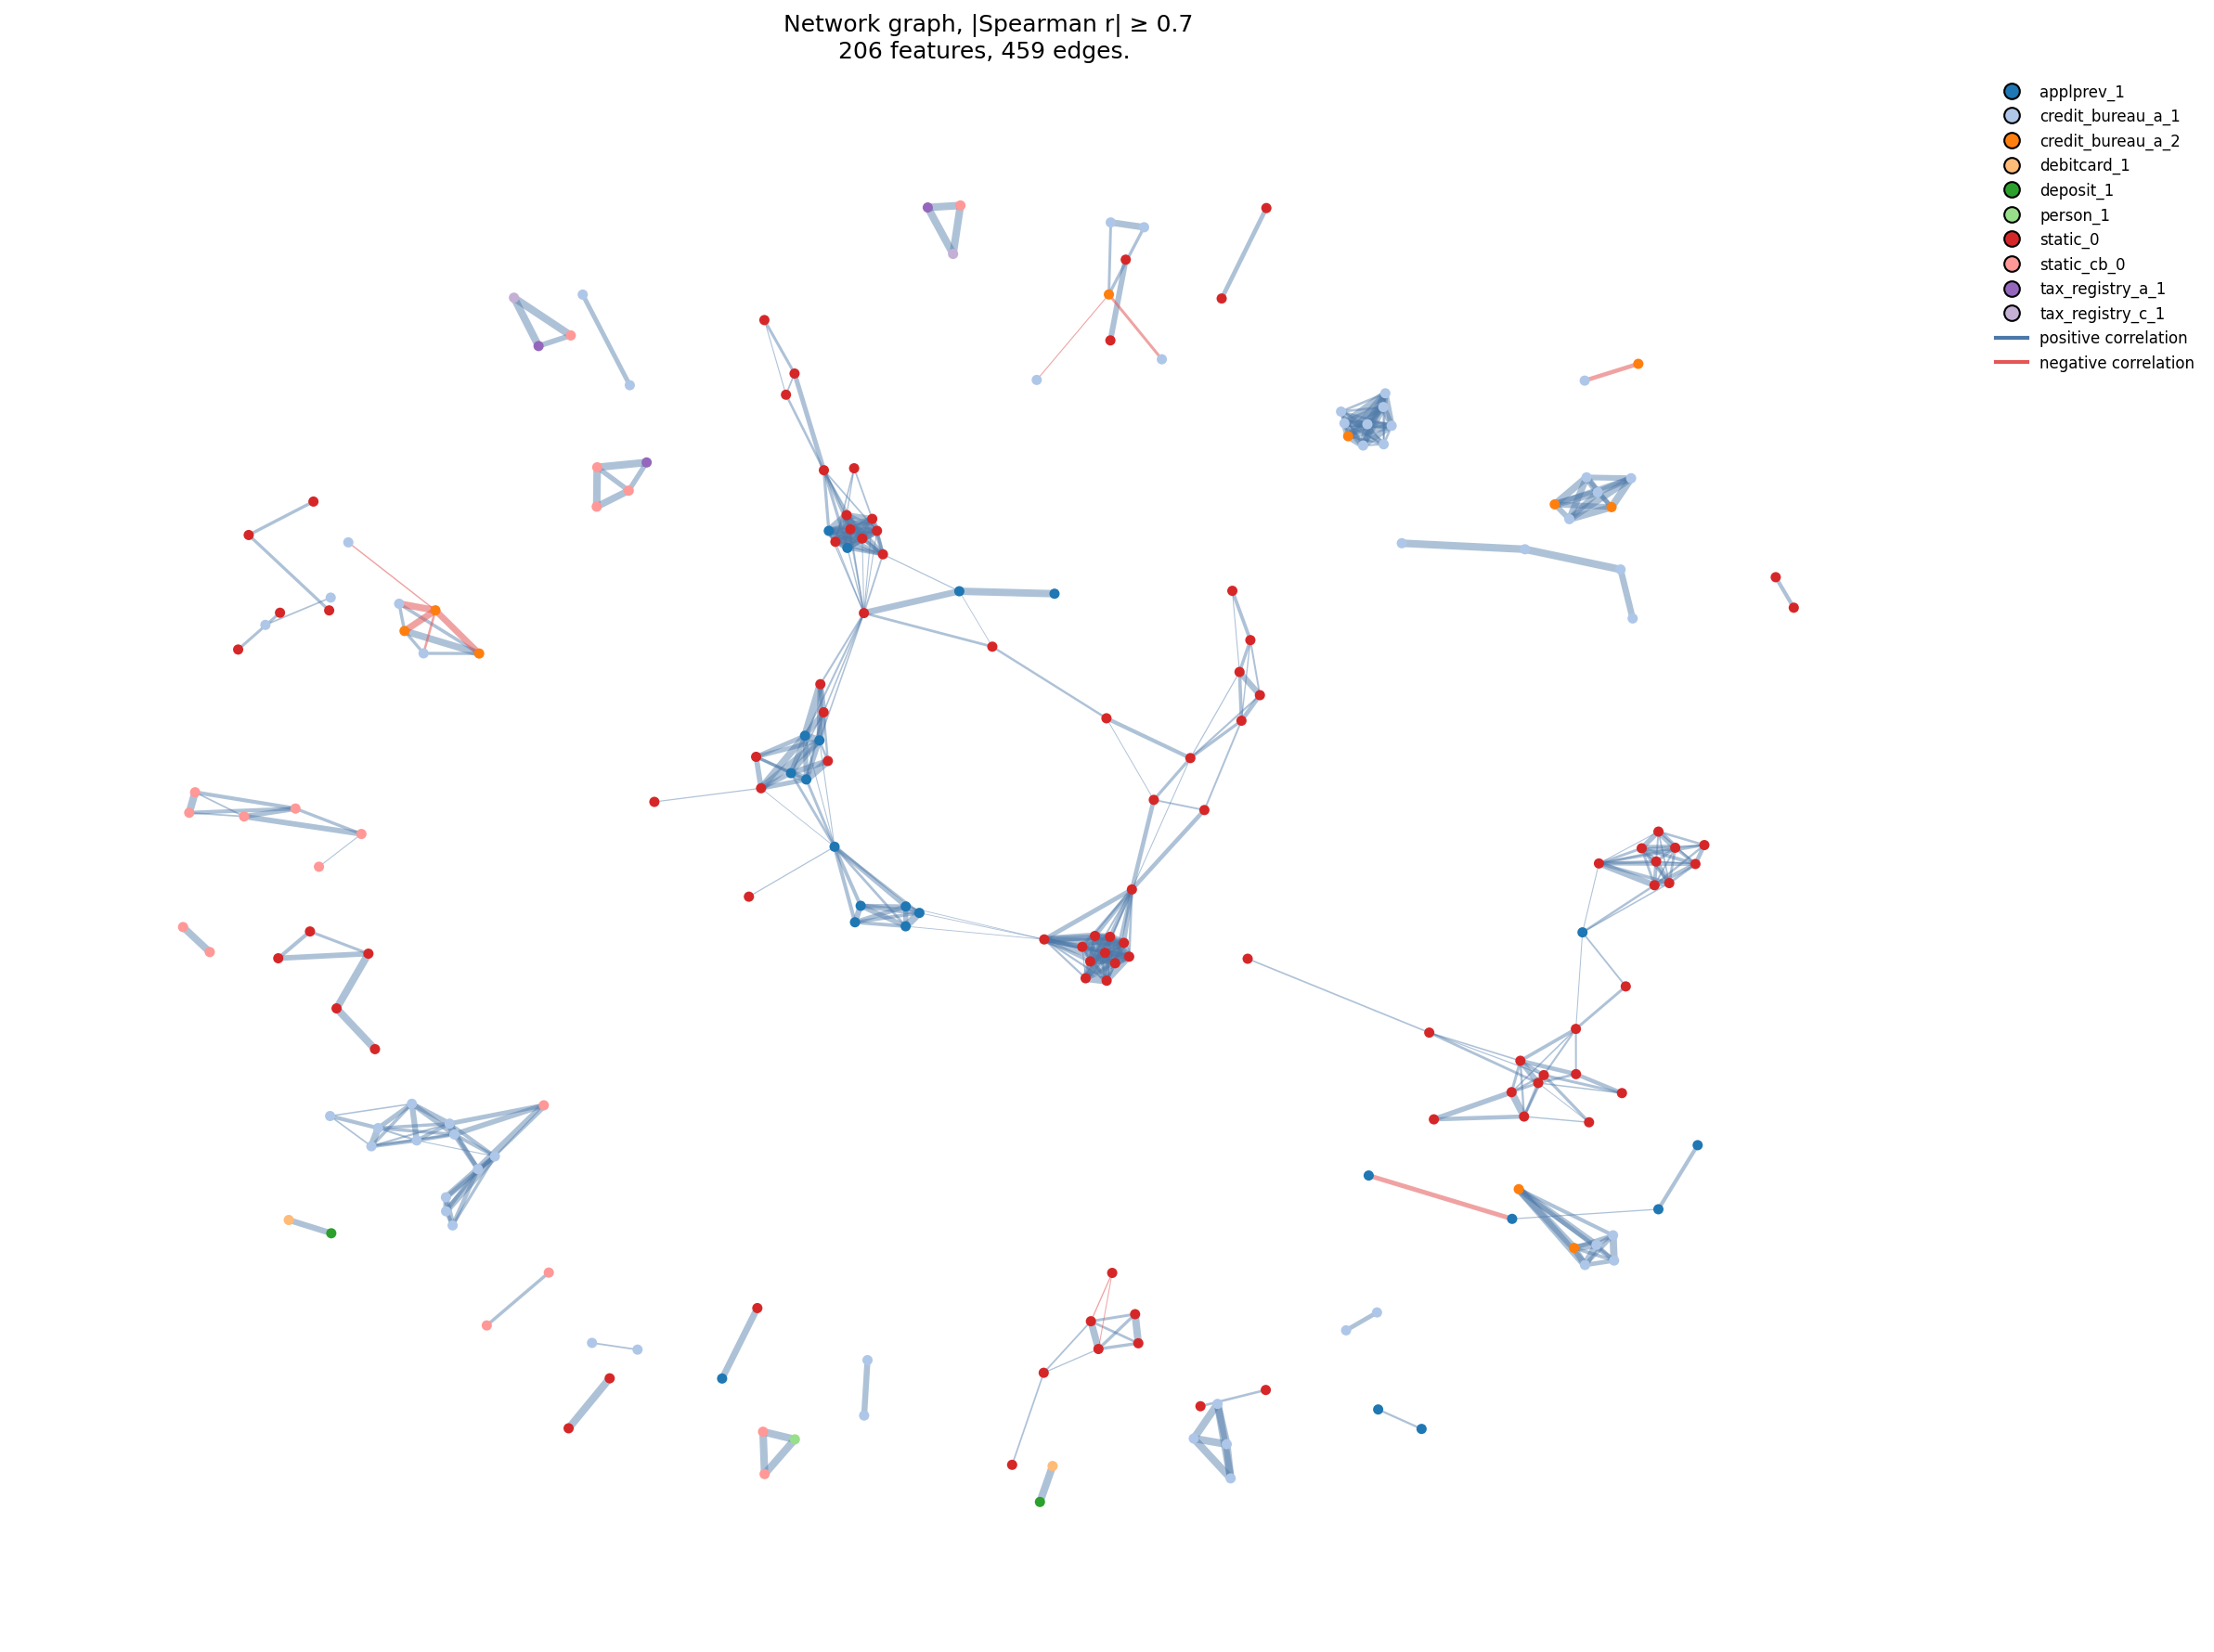

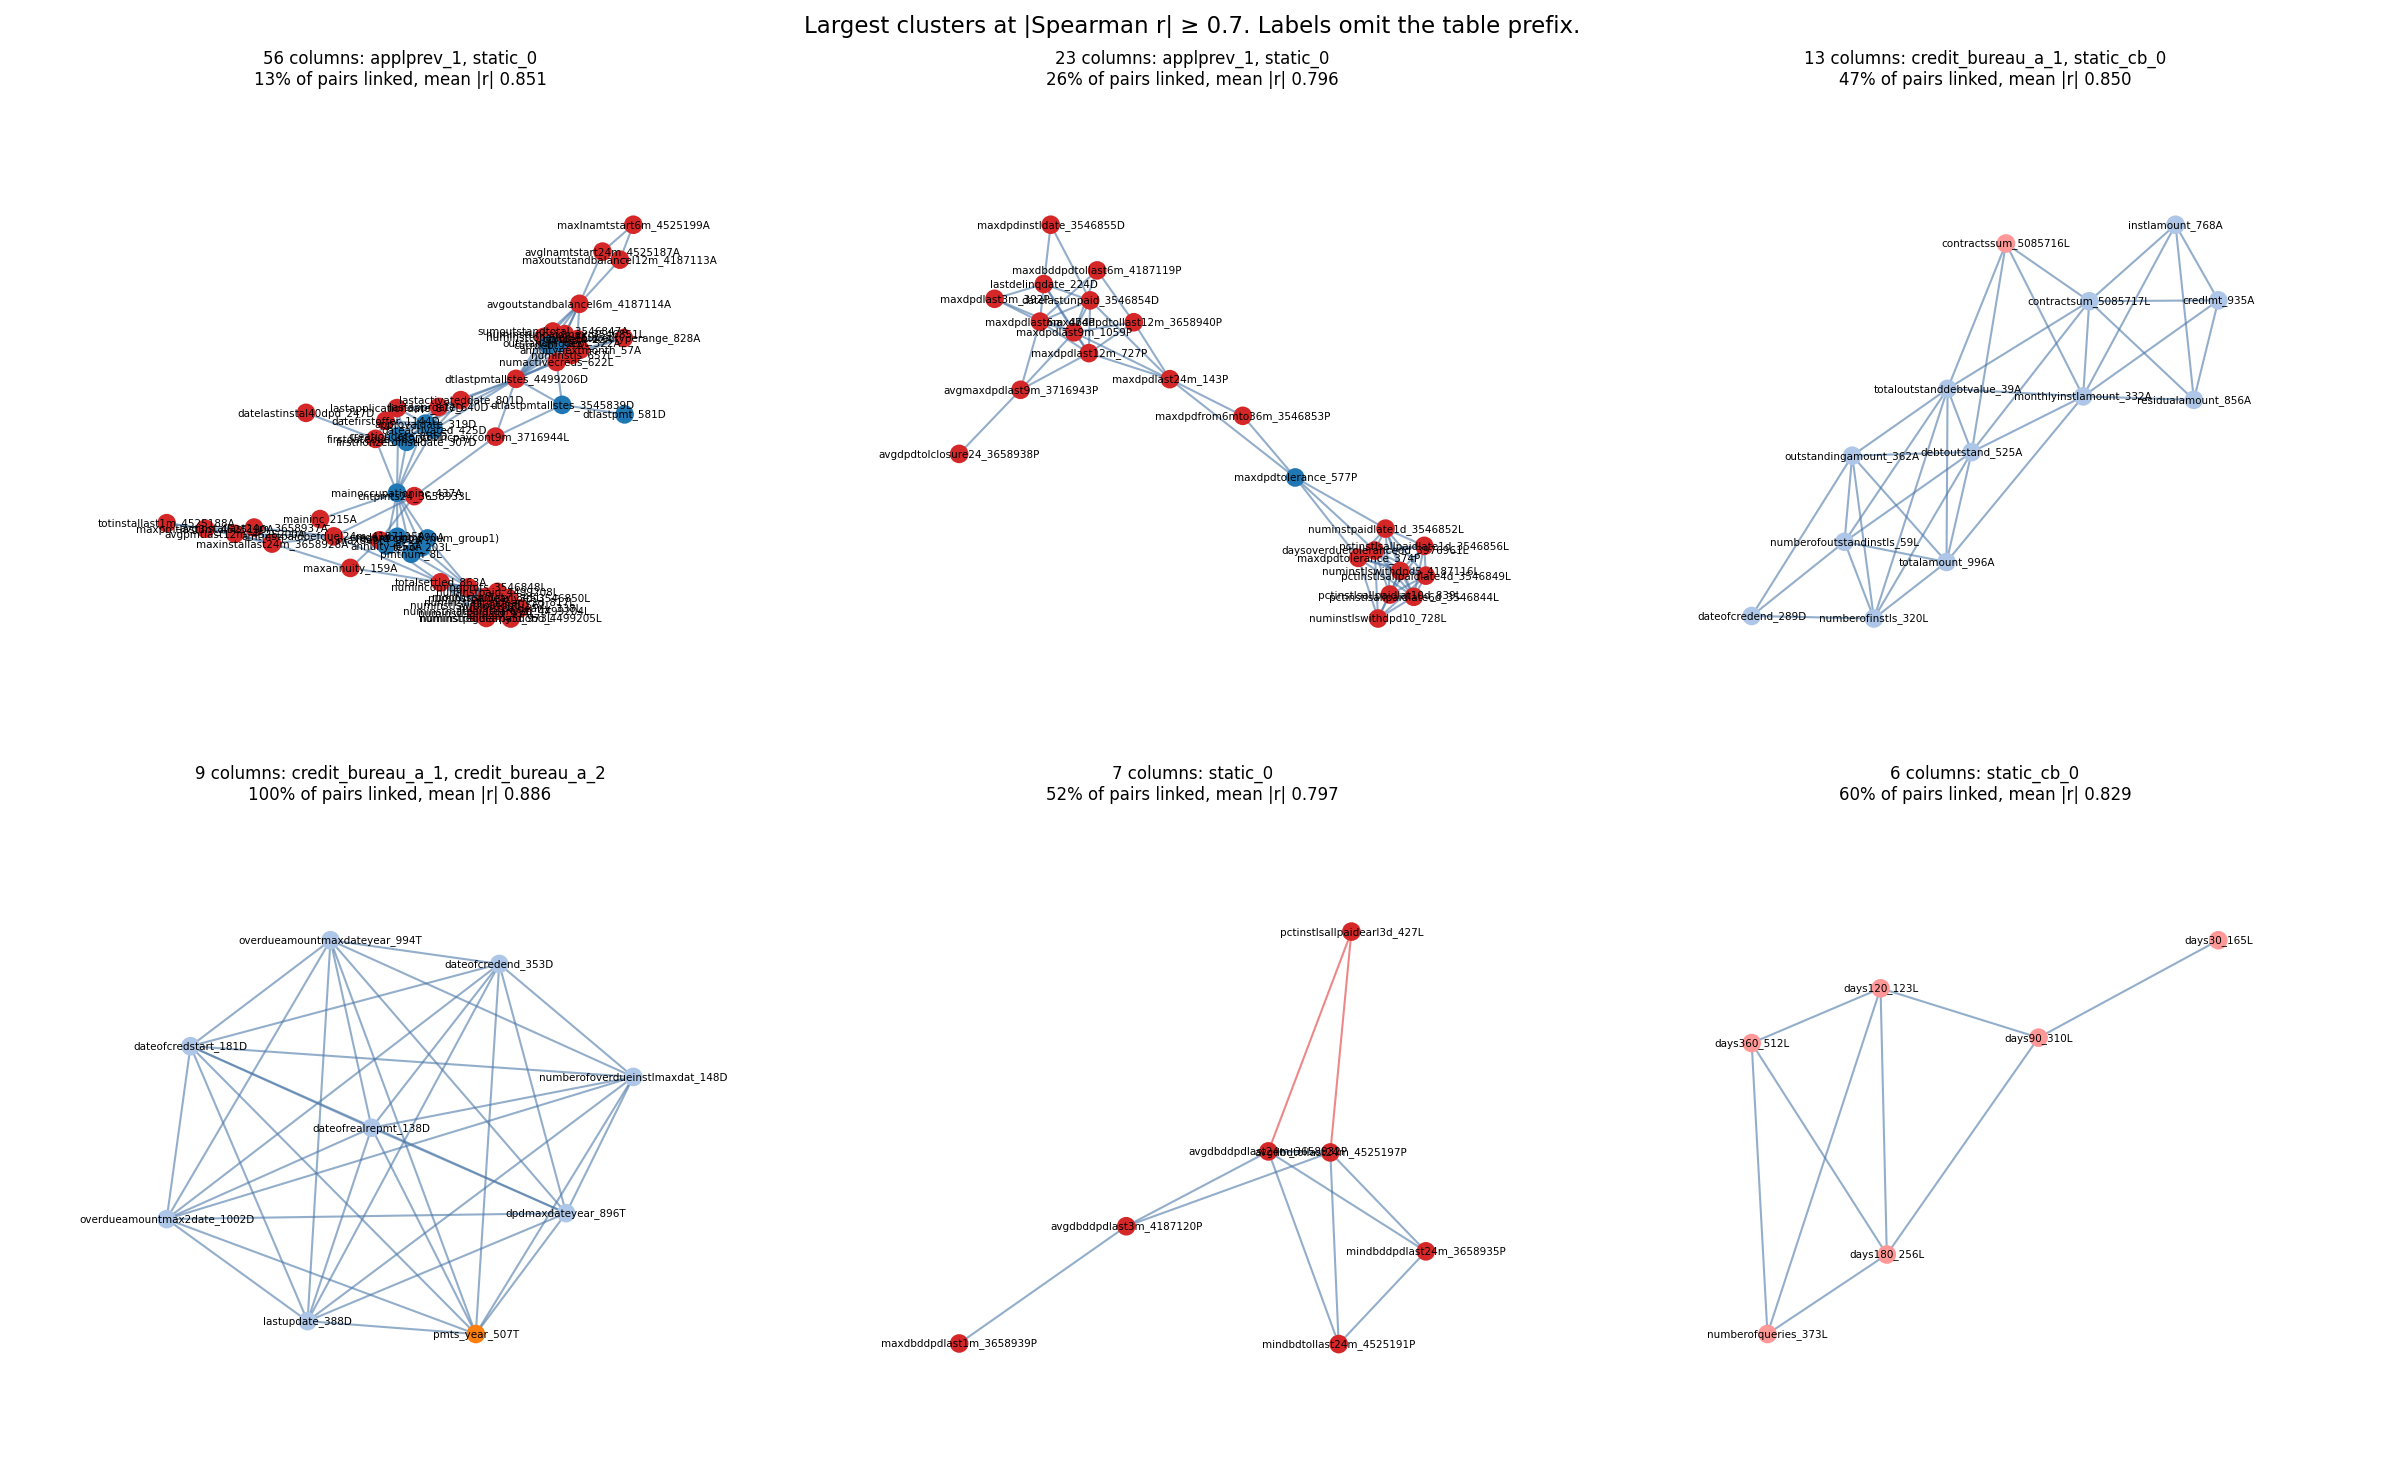

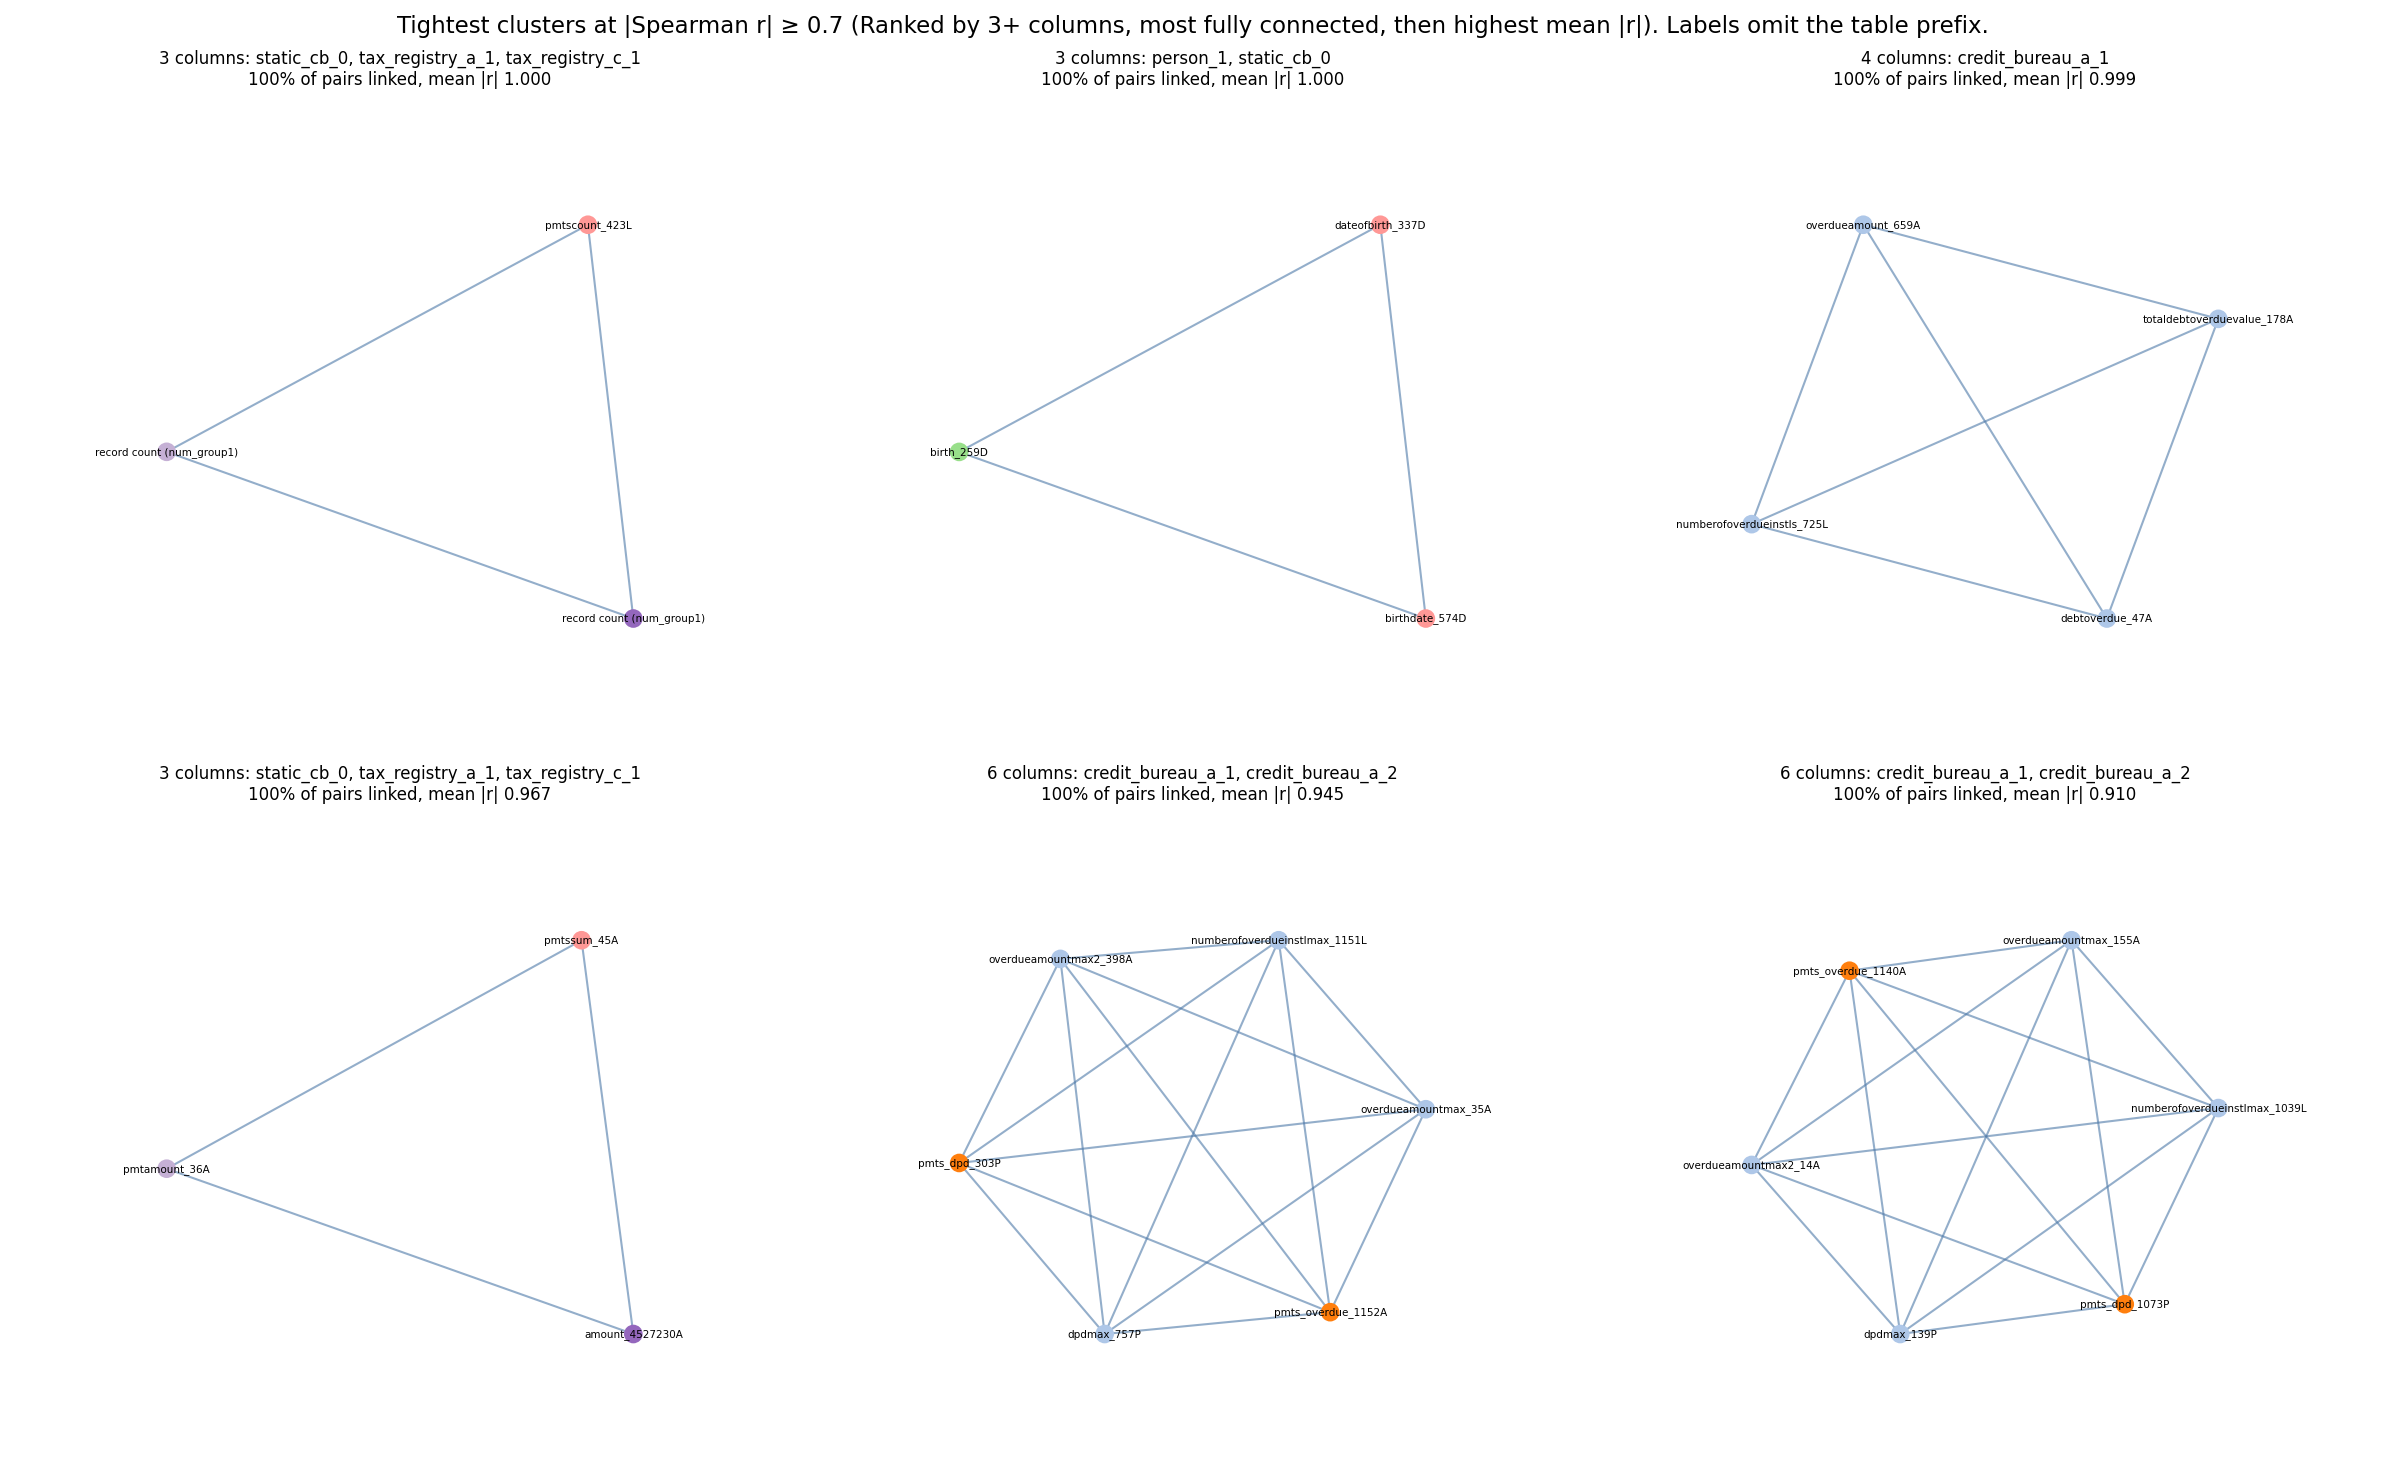

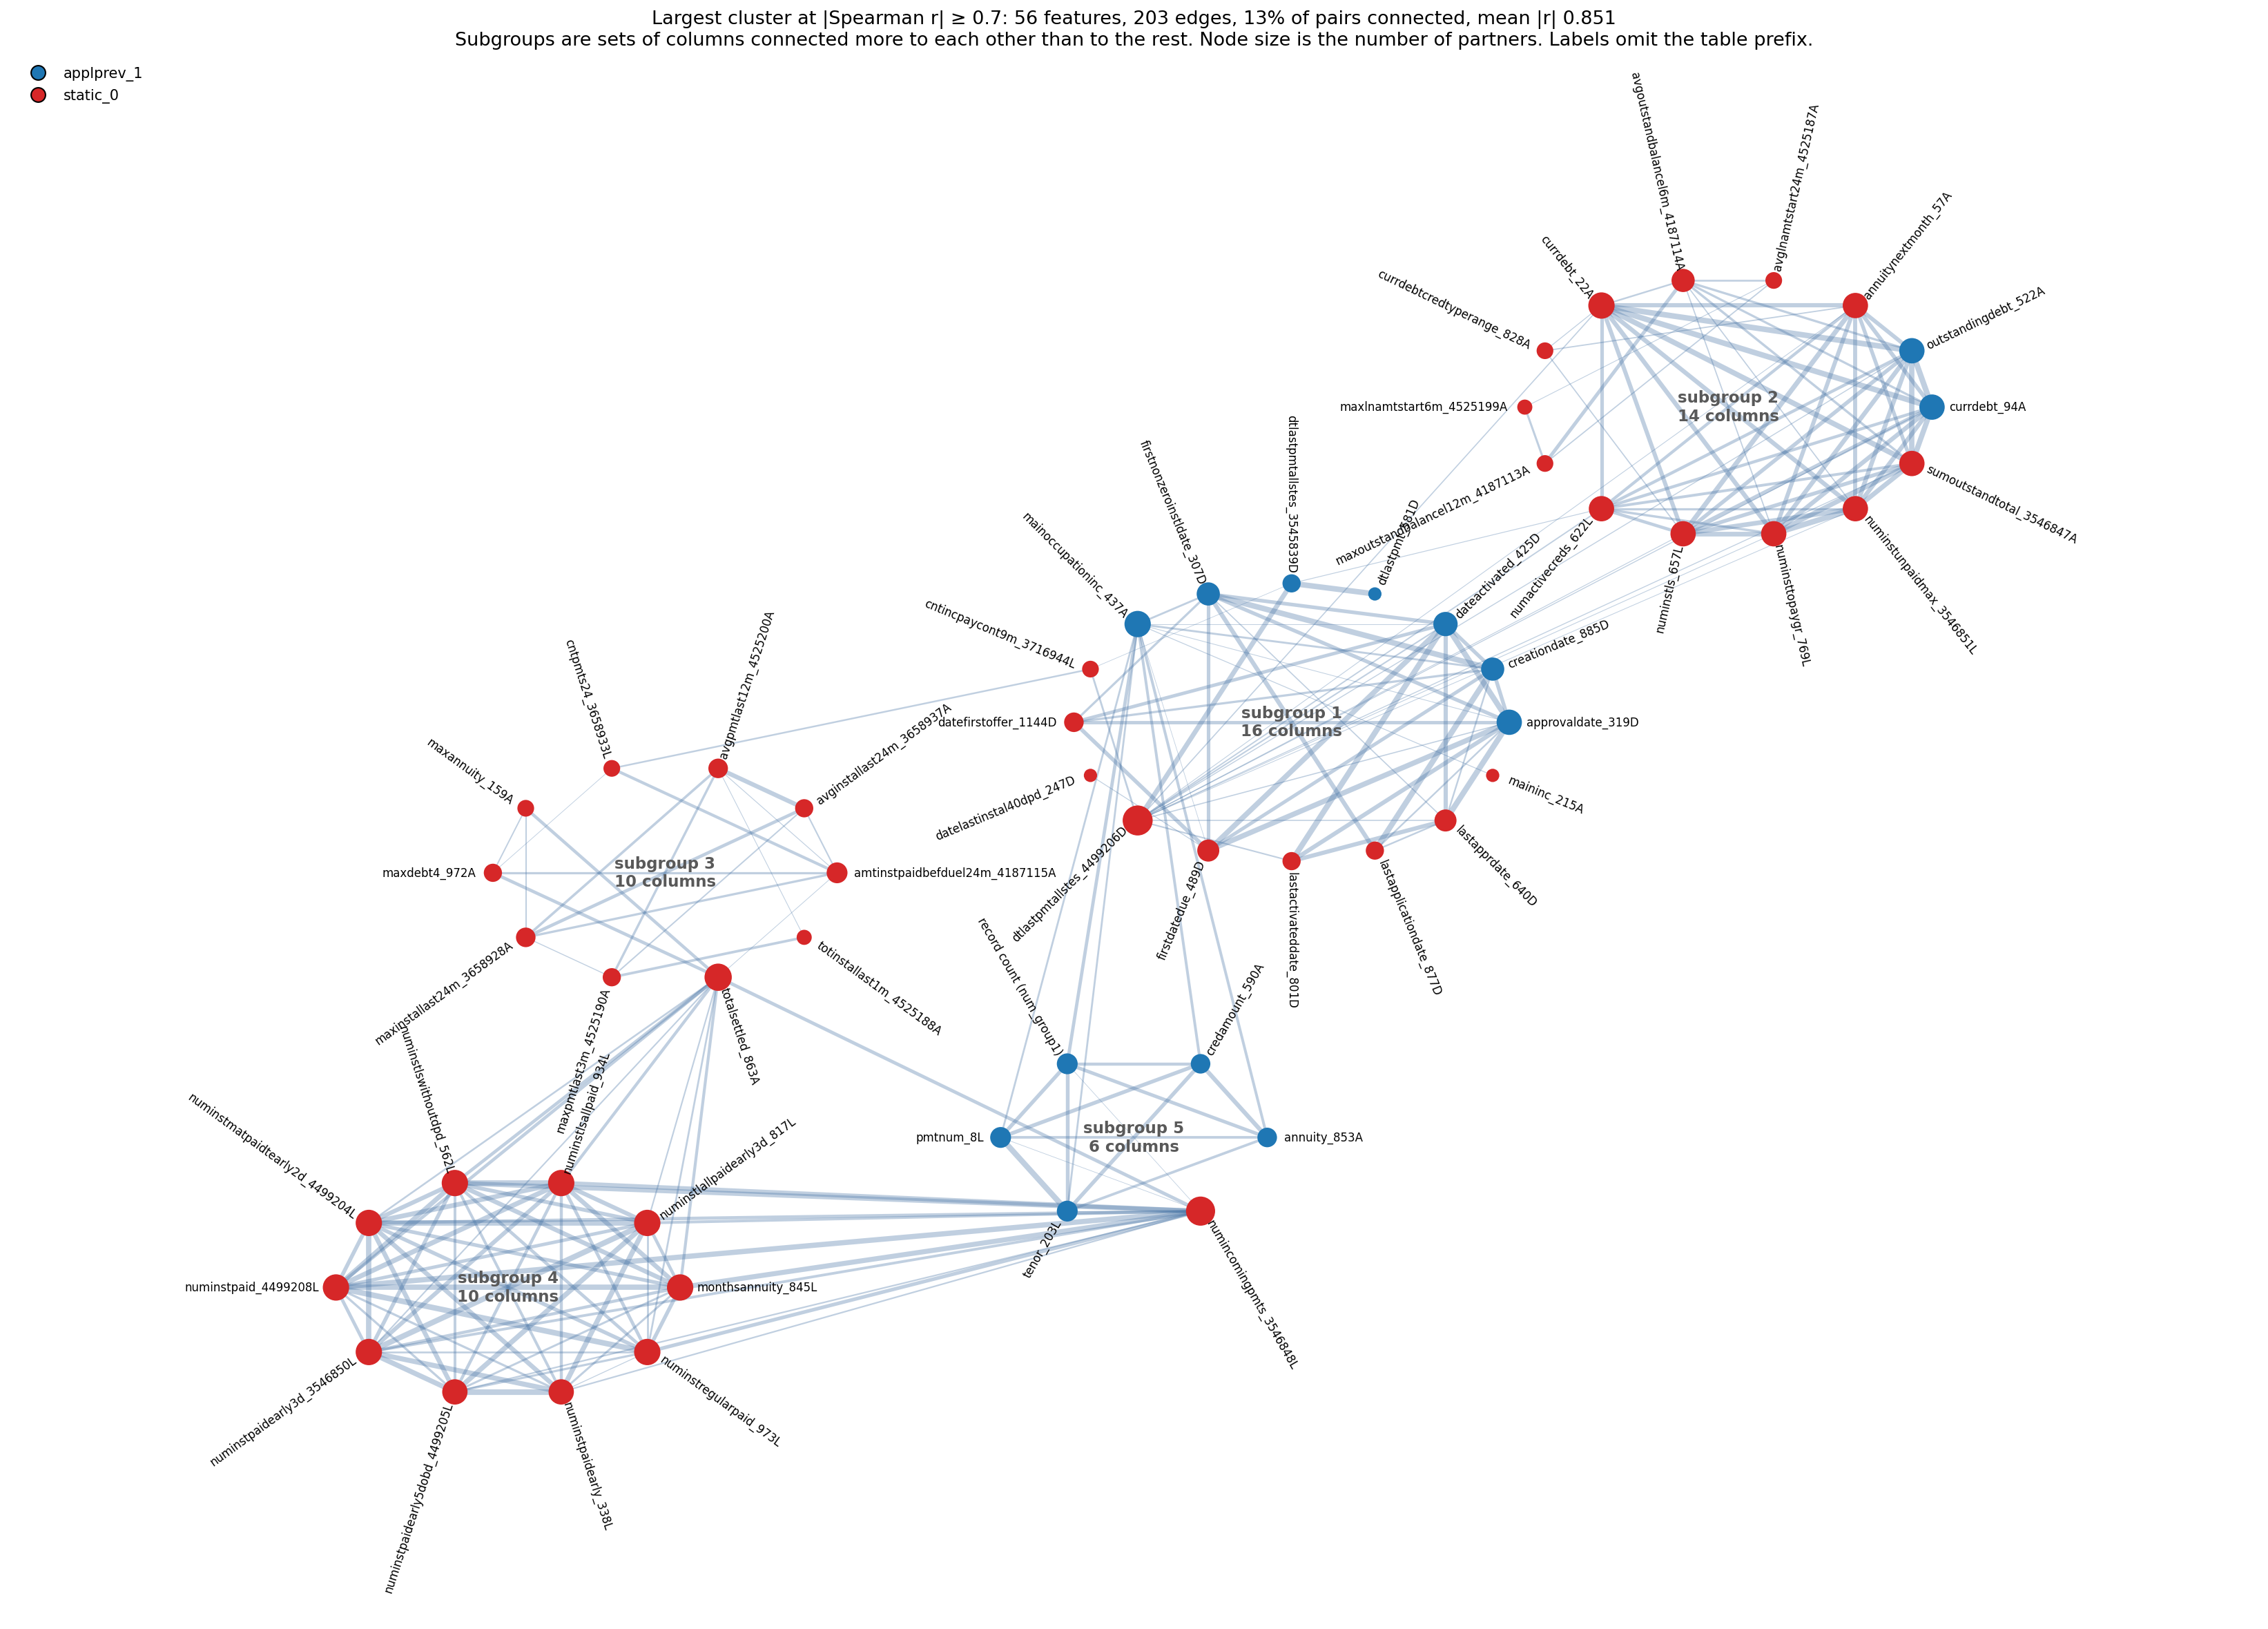

In [21]:
from IPython.display import Image, display

same = int(edges["same_column"].sum())
cross = int((~edges["same_table"]).sum())
same_category = int(edges["same_category"].sum())
print(f"{len(edges):,} edges at |r| >= {EDGE_THRESHOLD}")
print(f"{cross:,} features cross two tables")
print(f"{len(components)} clusters in the figure, cutoff {components['threshold'].iloc[0]}")
display(Image(filename=str(FIGURE)))
display(Image(filename=str(CLUSTERS_FIGURE)))
display(Image(filename=str(TIGHT_FIGURE)))
display(Image(filename=str(LARGEST_FIGURE)))